In [1]:
import pandas as pd
import missingno as msno
from pathlib import Path
import numpy as np

base_folder_path = Path("../")
metadata_folder_path = base_folder_path / "metadata" / "xlsx"

# Functions

In [2]:
def translate_col_entries(
    df: pd.DataFrame, colnames: list, replacement_dict: dict, verbose: bool = True
) -> tuple[pd.DataFrame, set]:
    """
    Translate entries in a column(s) of a df using a dictionary
    """
    # Get all dict values
    dict_values = set(replacement_dict.values())

    for colname in colnames:
        # Check if the column exists in the DataFrame
        if colname not in df.columns:
            print(f"Warning: Column {colname} not found in DataFrame.")
            continue
        # Remove leading and trailing whitespace
        df[colname] = df[colname].astype(str).str.strip()

        # Replace matched entries
        df[colname] = df[colname].replace(replacement_dict)
        # Identify all unique entries
        unique_entries = set(df[colname].unique())
        # Ensure all values are in the dictionary
        unknown_entries = unique_entries - dict_values

        # Convert to a list and remove nan
        unknown = [v for v in unknown_entries if v != "nan" and v != np.nan]
        if len(unknown) > 0:
            print(f"Warning: Unknown entries in {colname}: {unknown}")
    return df, unknown

# Aggregate and merge data

In [3]:
expected_cols = ["S/N",	"Month", "Collection Date", "Village", "Age", "Sex", "Fever", "Slide collected", "DBS collected", "Treatment History", "Travel History", "Field Sample collection ID", "RDT results", "Sample ID"]
aggregate_df = pd.DataFrame()
for file in metadata_folder_path.glob("*.xlsx"):
    df = pd.read_excel(file)
    
    # Ensure column names match
    if df.columns.tolist() != expected_cols:
        new = set(df.columns) - set(expected_cols)
        missing = set(expected_cols) - set(df.columns)
        print(f"Columns in {file.name} do not match expected columns.")
        print(f"New: {new}")
        print(f"Missing: {missing}")

    df['Collection Date'] = pd.to_datetime(df['Collection Date'], format='%d/%m/%Y', errors='coerce')
    
    df["health_facility"] = file.stem
    aggregate_df = pd.concat([aggregate_df, df], ignore_index=True)

In [4]:
#Check data is consistent
aggregate_df["Sample ID"] = aggregate_df["Sample ID"].astype("Int32")
dupes =aggregate_df[(aggregate_df.duplicated(subset=["Sample ID"], keep=False)) & aggregate_df["Sample ID"].notna()]
if dupes.shape[0] > 0:
    print(f"Warning: {dupes.shape[0]} duplicate Sample IDs found in the aggregated data.")

In [5]:
yes_no_dict = {
    "Yes": "Yes",
    "No": "No",
    "yes": "Yes",
    "no": "No",
    "YES": "Yes",
    "NO": "No",
    "Y": "Yes",
    "N": "No",
    "y": "Yes",
    "n": "No",
    "nil": "No",
    "Nil": "No",
    "N/A" : "No"
}
df , _ = translate_col_entries(df=aggregate_df, colnames=["Fever", "Slide collected", "DBS collected", "Treatment History", "Travel History"], replacement_dict=yes_no_dict, verbose=True)

# Data completeness

<Axes: >

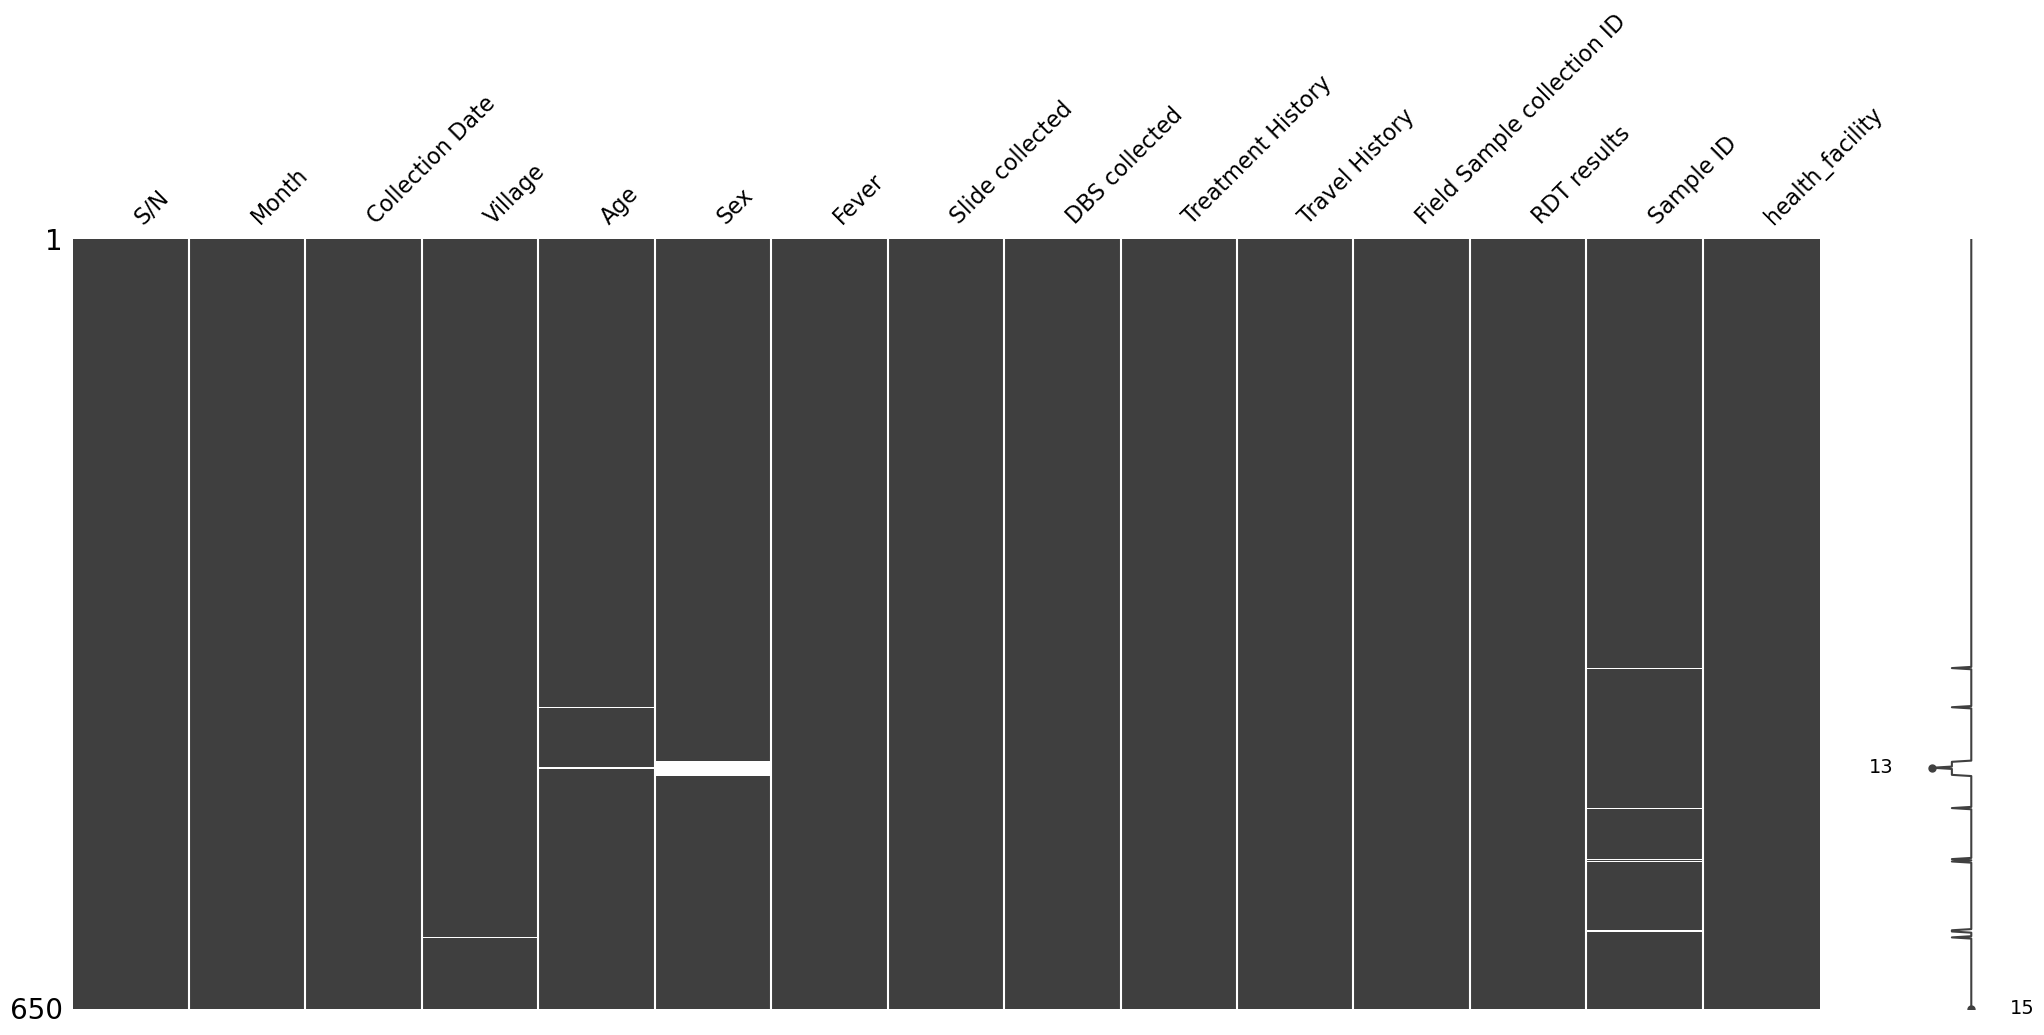

In [6]:
msno.matrix(aggregate_df)

In [8]:
aggregate_df.to_csv(base_folder_path / "metadata" / "Passive_MMS_Sample_metadata.csv", index=False)